<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Is delivering now     9551 non-null   object 
 15  Switch to order menu 

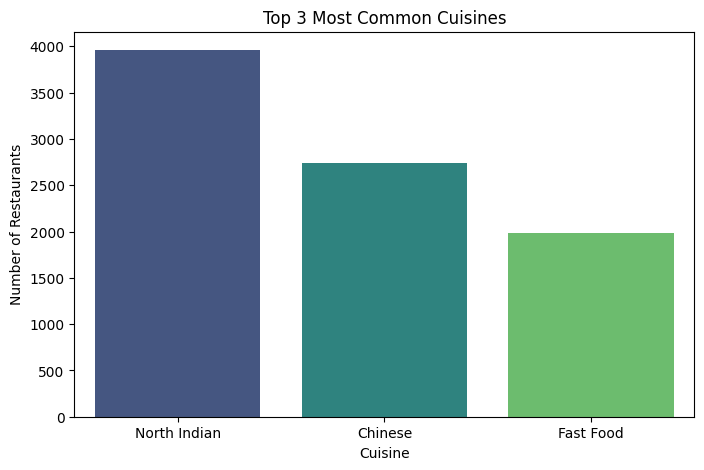

In [31]:
#TASK1
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#disaplay plots inside the natebook
%matplotlib inline

#load dataset
df= pd.read_csv("Dataset.csv")

# Display First Five rows
df.head()

# Dataset Information
df.info()

# Column Names
df.columns.tolist()

#Check Missing Values
df.isnull().sum()

# Display Cuisine Column
df["Cuisines"].head(10)
# Check Missing Values in Cuisine
df["Cuisines"].isnull().sum()

# Remove missing values
cuisines = df["Cuisines"].dropna()

# Split multiple cuisines
all_cuisines = cuisines.str.split(", ").explode()
#Count Each Cuisine
top_cuisines=all_cuisines.value_counts()

#Display top3 cuisines
top_3=top_cuisines.head(3)
print(top_3)

#calculate percentage
percentage=(top_3/len(df))*100
print(percentage)

#dispaly in table
result=pd.DataFrame({"Cuisine": top_3.index, "Count": top_3.values, "Percentage":percentage.values})
print(result)

# Create Bar Chart
plt.figure(figsize=(8,5))
sns.barplot(x=top_3.index,
            y=top_3.values,
            hue=top_3.index,
            palette="viridis",
            legend=False )
plt.title("Top 3 Most Common Cuisines")
plt.xlabel("Cuisine")
plt.ylabel("Number of Restaurants")
plt.show()

City
New Delhi    5473
Name: count, dtype: int64
City
Inner City    4.9
Name: Aggregate rating, dtype: float64


/tmp/ipykernel_800/1398560589.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


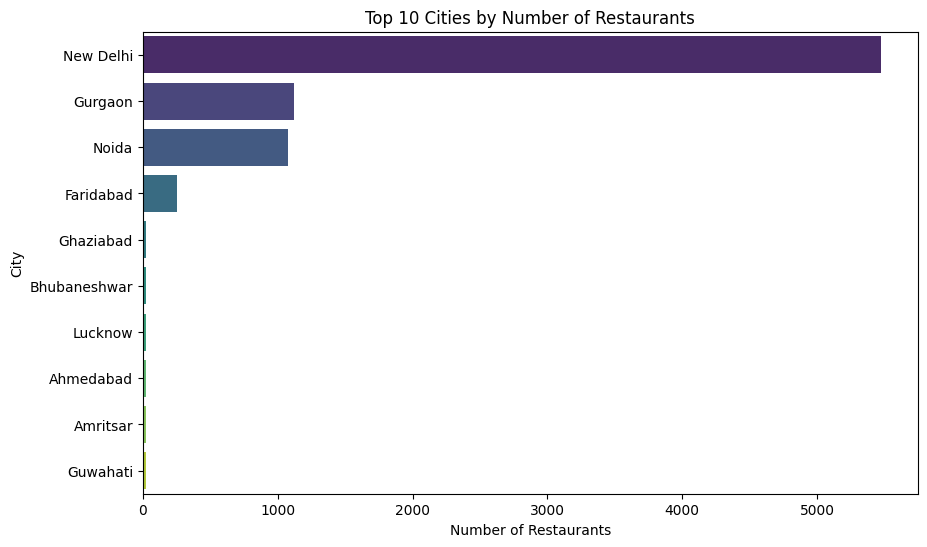

/tmp/ipykernel_800/1398560589.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


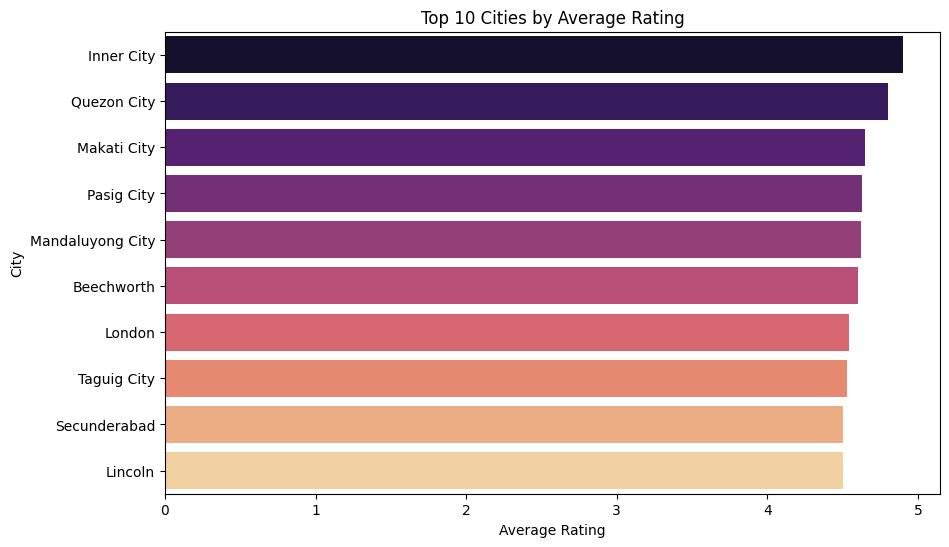

In [32]:
#TASK2

# Display first 10 city names
df["City"].head(10)

# Count the number of restaurants in each city
city_count = df["City"].value_counts()
city_count

# Display city with the highest number of restaurants
top_city = city_count.head(1)
print(top_city)

#Calculate average rating by city
average_rating = df.groupby("City")["Aggregate rating"].mean()
average_rating

#Round the ratings
average_rating = average_rating.round(2)
average_rating

#Find the Highest Rated City
highest_rated_city = average_rating.sort_values(ascending=False).head(1)
print(highest_rated_city)

#Create Result Table
result = pd.DataFrame({
    "Average Rating": average_rating
})
result.head()

#Bar Chart-Top 10 Cities by Numebr of Restaurants
plt.figure(figsize=(10,6))
sns.barplot(
    x=city_count.head(10).values,
    y=city_count.head(10).index,
    palette="viridis"
)
plt.title("Top 10 Cities by Number of Restaurants")
plt.xlabel("Number of Restaurants")
plt.ylabel("City")
plt.show()

# Bar Chart-Top 10 Cities by AverageRating
top_rating = average_rating.sort_values(ascending=False).head(10)
plt.figure(figsize=(10,6))
sns.barplot(
    x=top_rating.values,
    y=top_rating.index,
    palette="magma"
)
plt.title("Top 10 Cities by Average Rating")
plt.xlabel("Average Rating")
plt.ylabel("City")
plt.show()



Price range
1    4444
2    3113
3    1408
4     586
Name: count, dtype: int64
Price range
1    46.53
2    32.59
3    14.74
4     6.14
Name: count, dtype: float64


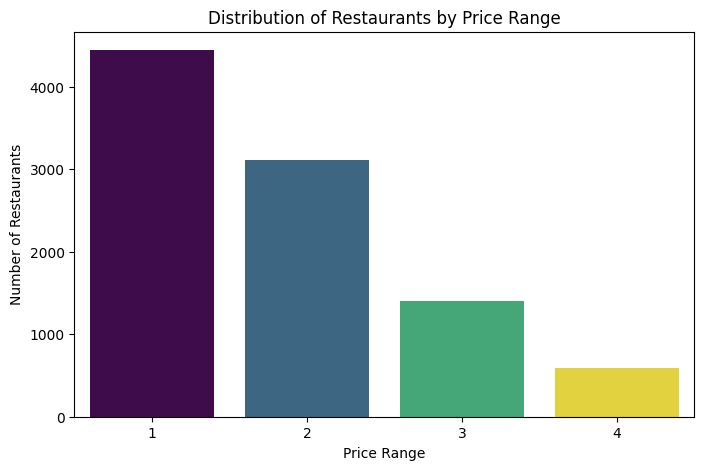

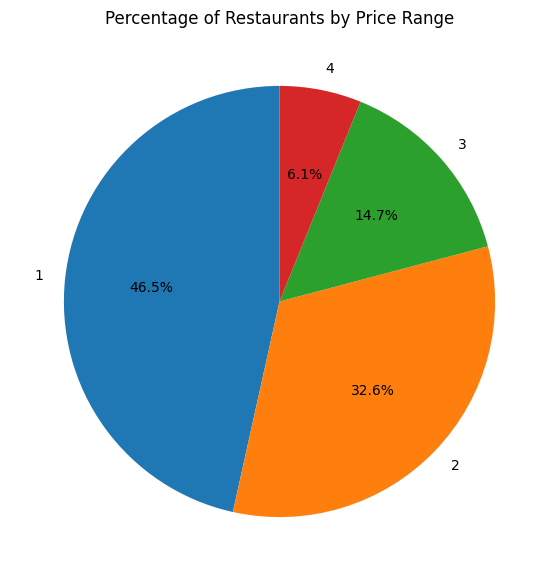

In [39]:
#Task3:Price range distribution

#Display first 10 price range values
df["Price range"].head(10)

#Count the restaurants in each price range
price_count=df["Price range"].value_counts().sort_index()
print(price_count)

#calculate percentage
price_percentage = (price_count / len(df)) * 100
price_percentage = price_percentage.round(2)
print(price_percentage)

#Create result table
result = pd.DataFrame({
    "Price Range": price_count.index,
    "Restaurant Count": price_count.values,
    "Percentage": price_percentage.values})
result

#Create Bar Chart
plt.figure(figsize=(8,5))
sns.barplot(x=price_count.index,
            y=price_count.values,
            hue=price_count.index,
            palette="viridis",
            legend=False)
plt.title("Distribution of Restaurants by Price Range")
plt.xlabel("Price Range")
plt.ylabel("Number of Restaurants")
plt.show()

#Create pie Chart
plt.figure(figsize=(7,7))
plt.pie(
    price_count.values,
    labels=price_count.index,
    autopct="%1.1f%%",
    startangle=90)
plt.title("Percentage of Restaurants by Price Range")
plt.show()

Has Online delivery
No     7100
Yes    2451
Name: count, dtype: int64
Has Online delivery
No     74.34
Yes    25.66
Name: count, dtype: float64
Has Online delivery
No     2.47
Yes    3.25
Name: Aggregate rating, dtype: float64


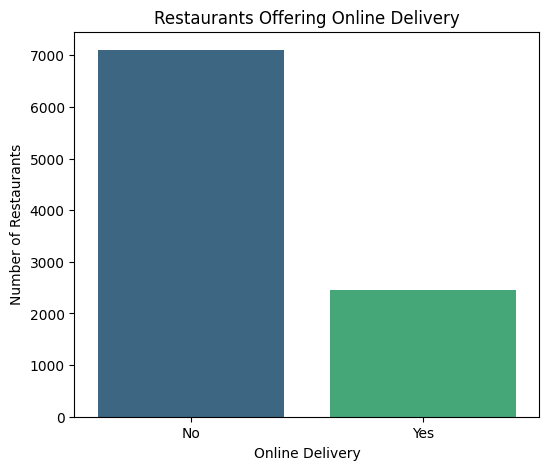

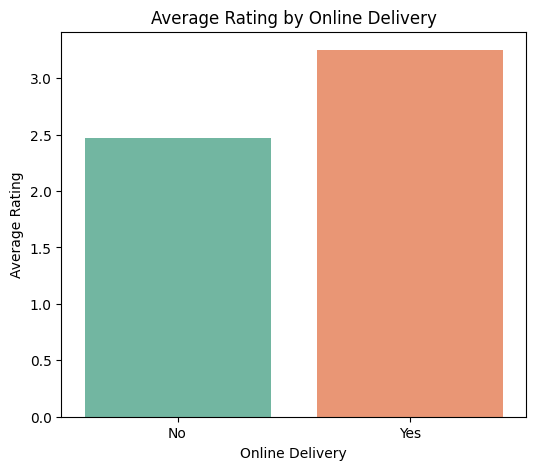

In [45]:
#Task 4:Online Delivery Anlysis

#Display first 10 values of has online delivery column
df["Has Online delivery"].head(10)

# Count restaurants offering online delivery
delivery_count = df["Has Online delivery"].value_counts()
print(delivery_count)

# Calculate percentage
delivery_percentage = (delivery_count / len(df)) * 100
delivery_percentage = delivery_percentage.round(2)
print(delivery_percentage)
len(df)

#Create a Result Table
result=pd.DataFrame({"Online Delivery":delivery_count.index,
                     "Restaurant Cont":delivery_count.values,
                     "Percentage":delivery_percentage.values})
result

#Compare Average Rating
average_rating = df.groupby("Has Online delivery")["Aggregate rating"].mean()
average_rating = average_rating.round(2)
print(average_rating)

#Display the Result in Table
rating_table = average_rating.reset_index()
rating_table.columns = ["Online Delivery", "Average Rating"]
rating_table

#Create a Bar Chart
plt.figure(figsize=(6,5))
sns.barplot(
    x=delivery_count.index,
    y=delivery_count.values,
    hue=delivery_count.index,
    palette="viridis",
    legend=False)
plt.title("Restaurants Offering Online Delivery")
plt.xlabel("Online Delivery")
plt.ylabel("Number of Restaurants")
plt.show()

#create a bar chart
plt.figure(figsize=(6,5))

sns.barplot(
    x=average_rating.index,
    y=average_rating.values,
    hue=average_rating.index,
    palette="Set2",
    legend=False
)

plt.title("Average Rating by Online Delivery")
plt.xlabel("Online Delivery")
plt.ylabel("Average Rating")

plt.show()